# Setup

## Imports

In [1]:
import os
import re
import json
import math
import pickle
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display, Markdown
from google.colab import drive

## Paths and Configuration

All input paths, output folders and experiment constants are set here, so any later section can be rerun after Setup alone.

In [4]:
# Drive
drive.mount('/content/drive')
PROJECT_DIR = '/content/drive/MyDrive/sc4001_nndl_grp_project'

# this notebook analyses the final test results
SPLIT = 'test'

# notebook folder
TRACK_DIR = os.path.join(PROJECT_DIR, 'phase_3', 'phase3_analysis')
if not os.path.isdir(TRACK_DIR):
    raise FileNotFoundError(TRACK_DIR + ' not found. Add sc4001_nndl_grp_project to My Drive as a shortcut.')

# inputs: test results from the Phase 3 test eval notebook
P2_RESULTS = os.path.join(PROJECT_DIR, 'phase_3', 'test_eval', 'results')
P1_BASELINE_RESULTS = os.path.join(PROJECT_DIR, 'phase_1', 'track_2', 'results')
COOC_PATH = os.path.join(PROJECT_DIR, 'phase_1', 'track_3', 'eval', 'cooccurrence_train.pkl')
for path in [P2_RESULTS, P1_BASELINE_RESULTS, COOC_PATH]:
    if not os.path.exists(path):
        raise FileNotFoundError(path)

# extra folders with results
EXTRA_RESULT_DIRS = []

# outputs
OUT_DIR = TRACK_DIR
PLOTS_DIR = os.path.join(OUT_DIR, 'plots')
TABLES_DIR = os.path.join(OUT_DIR, 'tables')
CACHE_DIR = os.path.join(OUT_DIR, 'cache')
FINDINGS_DIR = os.path.join(OUT_DIR, 'findings')
for d in [PLOTS_DIR, TABLES_DIR, CACHE_DIR, FINDINGS_DIR]:
    if os.path.isdir(d):
        print('exists ', d)
    else:
        os.makedirs(d)
        print('created', d)

BOOT_CACHE = os.path.join(CACHE_DIR, 'bootstrap.json')
FINDINGS_PATH = os.path.join(FINDINGS_DIR, 'findings.md')

# experiment
SEEDS = [0, 1, 2]
STD_DDOF = 0  # population std

# condition key: (loss, swap, margin, lambda)
# -1 means not used
BASELINE_KEY = ('margin', 'structured', 0.2, 0.0)
PHASE1_KEY = ('phase1', 'baseline', -1.0, -1.0)

# phase 1 baseline only has val results
INCLUDE_PHASE1_BASELINE = False

# lambda selection rule
MAX_CIDER_DROP = 2.0

# metrics are fractions in eval.json
# shown x100 except avg_len
METRICS = ['BLEU-4', 'METEOR', 'CIDEr', 'CHAIRi', 'CHAIRs', 'avg_len', 'obj_recall']
SCALE = {
    'BLEU-4': 100,
    'METEOR': 100,
    'CIDEr': 100,
    'CHAIRi': 100,
    'CHAIRs': 100,
    'avg_len': 1,
    'obj_recall': 100
}

# breakdowns
N_FREQ_BINS = 4
STRENGTH_EDGES = [0.0, 0.05, 0.1, 0.2, 0.4, 1.0001]
EXCLUDE_FROM_COOC = ['person']

# bootstrap
N_BOOT = 2000
BOOT_SEED = 42
BOOT_CHUNK = 250

# categorical colours per family, ordinal blue ramp for the lambda sweep
GREY = '#6b6b6b'
FAMILY_COLOUR = {
    'structured': '#2a78d6',
    'random': '#eb6834',
    'ul': '#1baf7a',
    'phase1': '#9a9a9a'
}
LAMBDA_RAMP = ['#86b6ef', '#5598e7', '#2a78d6', '#1c5cab', '#104281', '#0d366b']
matplotlib.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Liberation Sans', 'DejaVu Sans'],
    'font.size': 9,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.edgecolor': '#9a9a9a',
    'axes.grid': True,
    'grid.color': '#e6e6e6',
    'grid.linewidth': 0.6,
    'lines.linewidth': 1.8,
    'lines.markersize': 6,
    'legend.frameon': False,
    'savefig.dpi': 200,
    'savefig.bbox': 'tight'
})

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
created /content/drive/MyDrive/sc4001_nndl_grp_project/phase_3/phase3_analysis/plots
created /content/drive/MyDrive/sc4001_nndl_grp_project/phase_3/phase3_analysis/tables
created /content/drive/MyDrive/sc4001_nndl_grp_project/phase_3/phase3_analysis/cache
created /content/drive/MyDrive/sc4001_nndl_grp_project/phase_3/phase3_analysis/findings


In [3]:
print(os.listdir(os.path.join(PROJECT_DIR, 'phase_3')))

['test_eval', 'phase3_analysis']


## Shared Helpers

Used by every section below.

In [5]:
def read_json(path):
    with open(path) as fh:
        return json.load(fh)

def family(key):
    if key[0] == 'phase1':
        return 'phase1'
    if key[0] == 'unlikelihood':
        return 'ul'
    return key[1]

def label(key):
    if key == PHASE1_KEY:
        return 'phase 1 baseline'
    if key == BASELINE_KEY:
        return 'baseline (lam 0)'
    text = key[1] + ' lam ' + format(key[3], 'g')
    if key[0] == 'unlikelihood':
        return 'UL ' + text
    if key[2] != BASELINE_KEY[2]:
        text = text + ' m' + format(key[2], 'g')
    return text

def mean_std(values):
    # std is nan for a single seed so it is not read as zero spread
    arr = np.array(values, dtype=float)
    if len(arr) == 0:
        return float('nan'), float('nan')
    if len(arr) < 2:
        return float(arr.mean()), float('nan')
    return float(arr.mean()), float(arr.std(ddof=STD_DDOF))

def fmt_pm(m, s, digits=2):
    spec = '.' + str(digits) + 'f'
    if math.isnan(m):
        return '-'
    if math.isnan(s):
        return format(m, spec)
    return format(m, spec) + ' ± ' + format(s, spec)

def nan_to_zero(x):
    if math.isnan(x):
        return 0.0
    return x

def metric_stats(key, metric):
    values = []
    for seed in sorted(runs[key].keys()):
        values.append(runs[key][seed]['scores'][metric] * SCALE[metric])
    return mean_std(values)

def load_per_image(key, seed):
    # cached in memory
    # each file is 5000 records
    if (key, seed) not in per_image_cache:
        per_image_cache[(key, seed)] = read_json(runs[key][seed]['per_image'])
    return per_image_cache[(key, seed)]

def write_table(df, name):
    # csv for scripts
    # markdown and latex for the report
    df.to_csv(os.path.join(TABLES_DIR, name + '.csv'), index=False)
    cols = list(df.columns)
    md_lines = ['| ' + ' | '.join(cols) + ' |', '|' + '---|' * len(cols)]
    tex_lines = ['\\begin{tabular}{' + 'l' * len(cols) + '}', '\\hline',
                 ' & '.join(cols).replace('_', '\\_') + ' \\\\', '\\hline']
    for i, row in df.iterrows():
        cells = []
        for c in cols:
            cells.append(str(row[c]))
        md_lines.append('| ' + ' | '.join(cells) + ' |')
        tex_lines.append(' & '.join(cells).replace('±', '$\\pm$').replace('_', '\\_') + ' \\\\')
    tex_lines.append('\\hline')
    tex_lines.append('\\end{tabular}')
    with open(os.path.join(TABLES_DIR, name + '.md'), 'w') as fh:
        fh.write('\n'.join(md_lines) + '\n')
    with open(os.path.join(TABLES_DIR, name + '.tex'), 'w') as fh:
        fh.write('\n'.join(tex_lines) + '\n')

def save_fig(fig, name):
    fig.savefig(os.path.join(PLOTS_DIR, name + '.png'))
    fig.savefig(os.path.join(PLOTS_DIR, name + '.pdf'))

def sort_key(key):
    # baselines first, then family, margin, lambda
    order = {
        'phase1': 0,
        'structured': 1,
        'random': 2,
        'ul': 3
    }
    first = 1
    if key == PHASE1_KEY or key == BASELINE_KEY:
        first = 0
    return (first, order[family(key)], key[2], key[3])

def sweep_keys(loss, swap):
    # lambda > 0 conditions of one family, sorted by lambda
    found = []
    for key in KEYS:
        if key[0] == loss and key[1] == swap and key != BASELINE_KEY:
            found.append(key)
    return sorted(found, key=lambda k: k[3])

## Load Results

- Each training run is one (condition, seed) pair.
- A condition is a loss type, a negative type, a margin and a lambda.

In [6]:
P2_PATTERN = re.compile(r'^clipcap_objswap_(structured|random)_(ul_)?lam([0-9.]+)(?:_m([0-9.]+))?'
                        r'_transformer_p40_seed(\d+)_' + SPLIT + r'\.eval\.json$')
P1_PATTERN = re.compile(r'^clipcap_baseline_seed(\d+)_' + SPLIT + r'\.eval\.json$')

runs = {}
per_image_cache = {}

def add_run(key, seed, eval_path):
    stem = eval_path[:-len('.eval.json')]
    per_image = stem + '.per_image.json'
    swap_path = stem + '.swap_stats.json'
    if not os.path.exists(per_image):
        print('skipped, no per_image file:', os.path.basename(eval_path))
        return
    swap_stats = None
    if os.path.exists(swap_path):
        swap_stats = read_json(swap_path)
    if key not in runs:
        runs[key] = {}
    runs[key][seed] = {
        'scores': read_json(eval_path)['scores'],
        'per_image': per_image,
        'swap_stats': swap_stats
    }

for folder in [P2_RESULTS] + EXTRA_RESULT_DIRS:
    for fname in sorted(os.listdir(folder)):
        m = P2_PATTERN.match(fname)
        if m is None:
            continue
        swap_type, ul, lam, margin, seed = m.groups()
        if ul:
            key = ('unlikelihood', swap_type, -1.0, float(lam))
        else:
            key = ('margin', swap_type, float(margin), float(lam))
        if int(seed) in SEEDS:
            add_run(key, int(seed), os.path.join(folder, fname))

if INCLUDE_PHASE1_BASELINE:
    for fname in sorted(os.listdir(P1_BASELINE_RESULTS)):
        m = P1_PATTERN.match(fname)
        if m is not None and int(m.group(1)) in SEEDS:
            add_run(PHASE1_KEY, int(m.group(1)), os.path.join(P1_BASELINE_RESULTS, fname))

if BASELINE_KEY not in runs:
    raise RuntimeError('baseline (lambda 0) runs not found in ' + P2_RESULTS)
KEYS = sorted(runs.keys(), key=sort_key)
for key in KEYS:
    print(format(label(key), '<26'), 'seeds', sorted(runs[key].keys()))

# co-occurrence counts from train: COOC[o, g] = images containing both o and g
with open(COOC_PATH, 'rb') as fh:
    cooc = pickle.load(fh)
CATS = cooc['categories']
COOC = np.array(cooc['matrix'], dtype=float)
CAT_IDX = {}
for i, c in enumerate(CATS):
    CAT_IDX[c] = i

# COND[o, g] = P(o | g)
COND = COOC / np.maximum(np.diag(COOC)[None, :], 1)

baseline (lam 0)           seeds [0, 1, 2]
structured lam 3           seeds [0, 1, 2]
random lam 3               seeds [0, 1, 2]
UL structured lam 3        seeds [0, 1, 2]


# Results Table

## Method

For a metric $x$ measured on seeds $s = 1, \dots, S$, the mean is the plain average, and the std measures how far the seeds spread around it:

$$\bar{x} = \frac{1}{S}\sum_{s=1}^{S} x_s, \qquad \sigma^2 = \frac{1}{S - d}\sum_{s=1}^{S} (x_s - \bar{x})^2, \qquad \sigma = \sqrt{\sigma^2}$$

- $d$ is STD_DDOF.
- With $d = 0$ this is the population std, matching the Phase 1 baseline summary.
- The spread comes only from changing the seed, so it shows how much a number moves from training noise alone.
- The change columns are differences of means, $\Delta x = \bar{x}_{\text{condition}} - \bar{x}_{\text{baseline}}$.
- Negative $\Delta$ CHAIR means fewer hallucinations.
- Conditions with fewer than 3 seeds are provisional; the n column shows how many seeds are in.

## Helper Functions

In [7]:
def results_row(key, base_means):
    # one formatted row and one raw row per condition
    row = {
        'condition': label(key),
        'n': len(runs[key])
    }

    raw = {
        'condition': label(key),
        'loss': key[0],
        'swap': key[1],
        'margin': key[2],
        'lambda': key[3],
        'n_seeds': len(runs[key])
    }

    for metric in METRICS:
        m, s = metric_stats(key, metric)
        row[metric] = fmt_pm(m, s)
        raw[metric + '_mean'] = m
        raw[metric + '_std'] = s

    row['dCHAIRi'] = format(raw['CHAIRi_mean'] - base_means['CHAIRi'], '+.2f')
    row['dCHAIRs'] = format(raw['CHAIRs_mean'] - base_means['CHAIRs'], '+.2f')
    row['dCIDEr'] = format(raw['CIDEr_mean'] - base_means['CIDEr'], '+.2f')

    return row, raw

## Build Table

In [8]:
base_means = {}

for metric in METRICS:
    base_means[metric] = metric_stats(BASELINE_KEY, metric)[0]

rows = []
raw_rows = []

for key in KEYS:
    row, raw = results_row(key, base_means)
    rows.append(row)
    raw_rows.append(raw)

results_df = pd.DataFrame(rows)
write_table(results_df, 'results_table')
pd.DataFrame(raw_rows).to_csv(os.path.join(TABLES_DIR, 'results_table_raw.csv'), index=False)
results_df

,condition,n,BLEU-4,METEOR,CIDEr,CHAIRi,CHAIRs,avg_len,obj_recall,dCHAIRi,dCHAIRs,dCIDEr
0,baseline (lam 0),3,30.88 ± 0.24,26.45 ± 0.07,104.73 ± 0.39,6.80 ± 0.32,10.22 ± 0.49,9.81 ± 0.02,56.02 ± 0.13,+0.00,+0.00,+0.00
1,structured lam 3,3,30.69 ± 0.38,26.39 ± 0.10,104.52 ± 0.81,6.85 ± 0.22,10.23 ± 0.33,9.83 ± 0.03,55.88 ± 0.22,+0.05,+0.01,-0.21
2,random lam 3,3,30.91 ± 0.48,26.50 ± 0.15,105.09 ± 1.07,6.62 ± 0.23,10.01 ± 0.35,9.79 ± 0.01,55.86 ± 0.15,-0.19,-0.21,+0.36
3,UL structured lam 3,3,30.97 ± 0.19,26.36 ± 0.09,105.02 ± 0.35,6.92 ± 0.10,10.42 ± 0.07,9.78 ± 0.05,55.86 ± 0.01,+0.11,+0.20,+0.29


# CHAIR vs CIDEr Trade-off

## Method

- Each point is one condition at its mean over seeds, with error bars of one seed std on both axes.
- Each sweep family is joined in order of lambda, starting from the shared lambda 0 baseline, so the line traces the trade-off curve.
- Dashed lines mark the baseline.

A good condition moves left (lower CHAIR, fewer hallucinations) without moving down (lower CIDEr, worse captions).

## Helper Functions

In [9]:
def plot_condition(ax, key, x_metric):
    x, xs = metric_stats(key, x_metric)
    y, ys = metric_stats(key, 'CIDEr')
    colour = FAMILY_COLOUR[family(key)]
    face = colour
    marker = 'o'

    if key == BASELINE_KEY:
        colour = GREY
        face = GREY
        marker = 's'
    elif key == PHASE1_KEY:
        face = 'white'
        marker = 's'

    ax.errorbar(x, y, xerr=nan_to_zero(xs), yerr=nan_to_zero(ys), fmt=marker, color=colour, mfc=face,
                mec=colour, elinewidth=1, capsize=2, zorder=3)
    return x, y

def legend_handles():
    # one entry per family present
    names = {
        'baseline': 'baseline (lam 0)',
        'phase1': 'phase 1 baseline',
        'structured': 'co-occurrence negatives',
        'random': 'random negatives',
        'ul': 'unlikelihood loss'
    }

    handles = []
    seen = []

    for key in KEYS:
        name = family(key)

        if key == BASELINE_KEY:
            name = 'baseline'

        if name in seen:
            continue

        seen.append(name)
        colour = GREY
        face = GREY
        marker = 's'

        if name == 'phase1':
            face = 'white'
        elif name != 'baseline':
            colour = FAMILY_COLOUR[name]
            face = colour
            marker = 'o'

        handles.append(Line2D([], [], marker=marker, color=colour, mfc=face, ls='', label=names[name]))

    return handles

## Plot

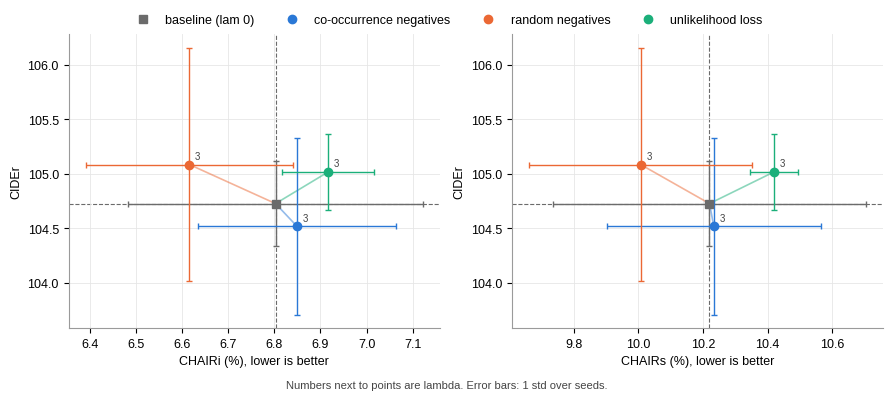

In [10]:
families = [('margin', 'structured'), ('margin', 'random'), ('unlikelihood', 'structured'), ('unlikelihood', 'random')]

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))

for ax, x_metric in zip(axes, ['CHAIRi', 'CHAIRs']):
    for loss, swap in families:
        line_keys = sweep_keys(loss, swap)

        if len(line_keys) == 0:
            continue

        line_keys = [BASELINE_KEY] + line_keys
        xs = []
        ys = []

        for key in line_keys:
            xs.append(metric_stats(key, x_metric)[0])
            ys.append(metric_stats(key, 'CIDEr')[0])

        ax.plot(xs, ys, '-', color=FAMILY_COLOUR[family(line_keys[-1])], alpha=0.5, lw=1.2, zorder=2)

    for key in KEYS:
        x, y = plot_condition(ax, key, x_metric)

        if key != PHASE1_KEY and key != BASELINE_KEY:
            ax.annotate(format(key[3], 'g'), (x, y), xytext=(4, 4), textcoords='offset points', fontsize=7, color='#444444')

    ax.axvline(metric_stats(BASELINE_KEY, x_metric)[0], color=GREY, ls='--', lw=0.8, zorder=1)
    ax.axhline(metric_stats(BASELINE_KEY, 'CIDEr')[0], color=GREY, ls='--', lw=0.8, zorder=1)
    ax.set_xlabel(x_metric + ' (%), lower is better')
    ax.set_ylabel('CIDEr')

handles = legend_handles()
fig.legend(handles=handles, loc='upper center', ncol=len(handles), bbox_to_anchor=(0.5, 1.05))
fig.text(0.5, -0.02, 'Numbers next to points are lambda. Error bars: 1 std over seeds.', ha='center', fontsize=8, color='#444444')
fig.tight_layout()
save_fig(fig, 'chair_vs_cider')
plt.show()

# Hallucination Breakdowns

## Method

Both breakdowns split the object mentions into groups and compute CHAIRi within each group. For a group $B$, counting over all val captions:

$$\text{rate}(B) = \frac{\text{hallucinated mentions of objects in } B}{\text{all mentions of objects in } B}$$

The rate is computed per seed, then averaged, with the seed std as the error bar.

**Object frequency:**   
$M_{o,g}$ is the number of train images containing both $o$ and $g$. Setting $g = o$ gives the number of images containing $o$ at all, so frequency is the diagonal, $f(o) = M_{o,o}$. The 80 objects are ranked by $f$ and split into four equal groups, Q1 (rarest) to Q4 (most common).

**Co-occurrence strength:**.  
How strongly does the rest of the image suggest $o$? The probability of $o$ given that $g$ is present is the share of $g$'s images that also contain $o$:

$$P(o \mid g) = \frac{\#\text{images with } o \text{ and } g}{\#\text{images with } g} = \frac{M_{o,g}}{M_{g,g}}$$

A mention of $o$ in an image with ground-truth objects $G$ gets the strongest link from any other object present:

$$\text{strength}(o) = \max_{g \in G,\ g \neq o} P(o \mid g)$$

and 0 if $o$ is the only ground-truth object. Mentions are then binned by strength.

POPE predicts that the rate rises with strength. A second version leaves out person: person co-occurs with almost everything, makes up about two thirds of the top bin, and is rarely hallucinated, so it hides the trend for the other objects.

## Helper Functions

In [11]:
def make_freq_bins():
    # object index -> quartile by train frequency, plus axis labels
    freq = np.diag(COOC)
    order = np.argsort(freq)
    bins = np.zeros(len(CATS), dtype=int)
    for rank, idx in enumerate(order):
        bins[idx] = rank * N_FREQ_BINS // len(CATS)
    labels = []
    for b in range(N_FREQ_BINS):
        members = freq[bins == b]
        labels.append('Q' + str(b + 1) + '\n' + str(int(members.min())) + '-' + str(int(members.max())))
    return bins, labels

def strength(obj, gt_objects):
    o = CAT_IDX[obj]
    best = 0.0
    for g in gt_objects:
        if g == obj:
            continue
        p = COND[o, CAT_IDX[g]]
        if p > best:
            best = p
    return best

def strength_bin(s):
    for b in range(len(STRENGTH_EDGES) - 1):
        if s < STRENGTH_EDGES[b + 1]:
            return b
    return len(STRENGTH_EDGES) - 2

def strength_labels():
    labels = []
    for b in range(len(STRENGTH_EDGES) - 1):
        hi = min(STRENGTH_EDGES[b + 1], 1.0)
        labels.append(format(STRENGTH_EDGES[b], 'g') + '-' + format(hi, 'g'))
    return labels

def freq_bin_of(obj, rec):
    # uses freq_bins from make_freq_bins
    # set in By Object Frequency
    return freq_bins[CAT_IDX[obj]]

def cooc_bin_of(obj, rec):
    return strength_bin(strength(obj, rec['gt_objects']))

def cooc_bin_excluding(obj, rec):
    if obj in EXCLUDE_FROM_COOC:
        return -1
    return cooc_bin_of(obj, rec)

def binned_counts(records, bin_of, n_bins):
    # bin_of(obj, rec) gives a bin index or -1 to skip the mention
    hal = np.zeros(n_bins)
    tot = np.zeros(n_bins)
    for rec in records:
        hset = set(rec['hallucinated_objects'])
        for obj in rec['mentioned_objects']:
            b = bin_of(obj, rec)
            if b < 0:
                continue
            tot[b] += 1
            if obj in hset:
                hal[b] += 1
    return hal, tot

def breakdown(bin_of, n_bins, bin_labels):
    # per condition: mean and std over seeds of the rate per bin, plus mentions per seed
    stats = {}
    rows = []
    for key in KEYS:
        rates = []
        mention_sum = np.zeros(n_bins)
        for seed in sorted(runs[key].keys()):
            hal, tot = binned_counts(load_per_image(key, seed), bin_of, n_bins)
            rates.append(100 * hal / np.maximum(tot, 1))
            mention_sum += tot
        rates = np.array(rates)
        means = np.zeros(n_bins)
        stds = np.zeros(n_bins)
        for b in range(n_bins):
            means[b], stds[b] = mean_std(rates[:, b])
            rows.append({
                'condition': label(key),
                'bin': bin_labels[b].replace('\n', ' '),
                'rate_mean': means[b],
                'rate_std': stds[b],
                'mentions_per_seed': mention_sum[b] / len(rates)
            })
        stats[key] = (means, stds)
    return stats, pd.DataFrame(rows)

def save_breakdown_table(raw_df, name):
    # raw csv for findings
    # formatted table for the report
    raw_df.to_csv(os.path.join(TABLES_DIR, name + '_raw.csv'), index=False)
    rows = []
    for _, r in raw_df.iterrows():
        rows.append({
            'condition': r['condition'],
            'bin': r['bin'],
            'rate': fmt_pm(r['rate_mean'], r['rate_std']),
            'mentions_per_seed': int(round(r['mentions_per_seed']))
        })
    df = pd.DataFrame(rows)
    write_table(df, name)
    return df

def plot_breakdown(stats, bin_labels, x_title, name):
    # baseline grey, structured sweep on the blue ramp, other families dashed
    sweep = sweep_keys('margin', 'structured')
    fig, ax = plt.subplots(figsize=(6, 3.4))
    x = np.arange(len(bin_labels))
    for key in KEYS:
        if key == PHASE1_KEY:
            continue
        means, stds = stats[key]
        err = np.nan_to_num(stds)
        if key == BASELINE_KEY:
            ax.errorbar(x, means, yerr=err, fmt='-s', color=GREY, lw=2.2, capsize=2, label=label(key), zorder=4)
        elif key in sweep:
            colour = LAMBDA_RAMP[min(sweep.index(key), len(LAMBDA_RAMP) - 1)]
            ax.errorbar(x, means, yerr=err, fmt='-o', color=colour, capsize=2, label=label(key), zorder=3)
        else:
            ax.errorbar(x, means, yerr=err, fmt='--^', color=FAMILY_COLOUR[family(key)], capsize=2, label=label(key), zorder=3)

    ax.set_xticks(x)
    ax.set_xticklabels(bin_labels)
    ax.set_xlabel(x_title)
    ax.set_ylabel('hallucination rate (%)')
    ax.legend(fontsize=7, loc='upper left', bbox_to_anchor=(1.0, 1.0))
    fig.tight_layout()
    save_fig(fig, name)
    plt.show()

## By Object Frequency

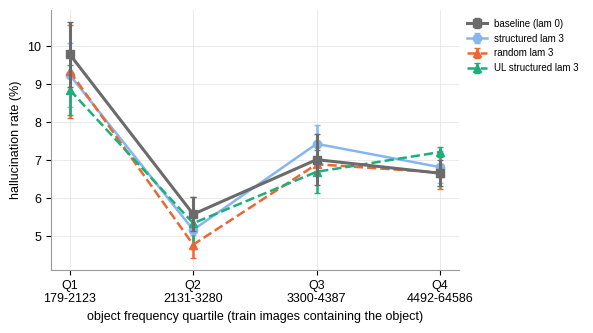

,condition,bin,rate,mentions_per_seed
0,baseline (lam 0),Q1 179-2123,9.78 ± 0.85,706
1,baseline (lam 0),Q2 2131-3280,5.58 ± 0.44,1505
2,baseline (lam 0),Q3 3300-4387,7.02 ± 0.68,1628
3,baseline (lam 0),Q4 4492-64586,6.66 ± 0.35,4330


In [12]:
freq_bins, freq_labels = make_freq_bins()
freq_stats, freq_raw = breakdown(freq_bin_of, N_FREQ_BINS, freq_labels)
freq_df = save_breakdown_table(freq_raw, 'halluc_by_frequency')
plot_breakdown(freq_stats, freq_labels, 'object frequency quartile (train images containing the object)', 'halluc_by_frequency')
freq_df[freq_df['condition'] == label(BASELINE_KEY)]

## By Co-occurrence Strength

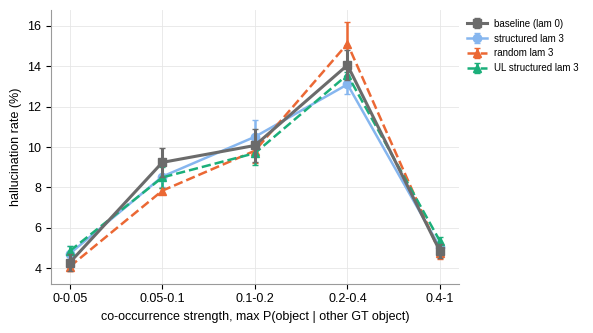

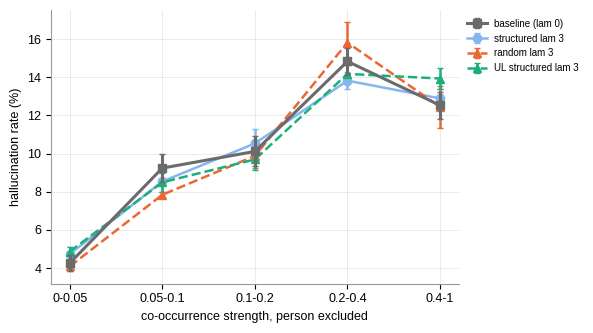

,condition,bin,rate,mentions_per_seed
0,baseline (lam 0),0-0.05,4.26 ± 0.43,1916
1,baseline (lam 0),0.05-0.1,9.24 ± 0.74,1031
2,baseline (lam 0),0.1-0.2,10.11 ± 0.79,1027
3,baseline (lam 0),0.2-0.4,14.83 ± 0.69,728
4,baseline (lam 0),0.4-1,12.53 ± 0.69,1155


In [13]:
n_strength_bins = len(STRENGTH_EDGES) - 1
cooc_labels = strength_labels()
cooc_stats, cooc_raw = breakdown(cooc_bin_of, n_strength_bins, cooc_labels)
cooc_df = save_breakdown_table(cooc_raw, 'halluc_by_cooccurrence')
plot_breakdown(cooc_stats, cooc_labels, 'co-occurrence strength, max P(object | other GT object)', 'halluc_by_cooccurrence')

excl_stats, excl_raw = breakdown(cooc_bin_excluding, n_strength_bins, cooc_labels)
excl_df = save_breakdown_table(excl_raw, 'halluc_by_cooccurrence_no_person')
plot_breakdown(excl_stats, cooc_labels, 'co-occurrence strength, ' + ', '.join(EXCLUDE_FROM_COOC) + ' excluded', 'halluc_by_cooccurrence_no_person')
excl_df[excl_df['condition'] == label(BASELINE_KEY)]

# Paired Bootstrap

## Method

The question is whether a condition's CHAIR differs from the baseline by more than the luck of which images ended up in val. Both models caption the same val images, so the test is paired: each bootstrap draw resamples images with replacement and scores both models on the same draw.

Drawing $N$ images with replacement is the same as giving image $i$ a weight $w_i$, the number of times it was drawn. CHAIRi is total hallucinated mentions over total mentions. In a draw, each image counts $w_i$ times, so for seed $s$ with $h_{s,i}$ hallucinated mentions and $m_{s,i}$ mentions in image $i$:

$$\text{CHAIRi}_s^* = \frac{\sum_i w_i\, h_{s,i}}{\sum_i w_i\, m_{s,i}}, \qquad \text{CHAIRs}_s^* = \frac{\sum_i w_i\, \mathbb{1}[h_{s,i} > 0]}{\sum_i w_i}$$

Each is averaged over the seeds in the comparison, $\text{CHAIR}^* = \frac{1}{S}\sum_s \text{CHAIR}_s^*$. Seeds are paired too: condition seed $s$ is compared against baseline seed $s$.

For each draw, $\Delta^* = \text{CHAIR}^*_{\text{condition}} - \text{CHAIR}^*_{\text{reference}}$. Repeating this N_BOOT times gives a distribution of $\Delta^*$:
- The 95% CI is its 2.5th to 97.5th percentile.
- If the condition made no difference, $\Delta^*$ would land on either side of 0 about equally often, so the two-sided p value is twice the smaller tail: $p = 2 \min\left(P(\Delta^* \ge 0),\ P(\Delta^* \le 0)\right)$, capped at 1.

A difference is significant at 5% when the CI does not contain 0.

Comparisons are every condition against the lambda 0 baseline, plus random against co-occurrence negatives at the same lambda (the ablation). Each finished comparison is saved to the Drive cache and skipped on rerun, unless its seeds or N_BOOT changed.

## Helper Functions

In [14]:
def hm_arrays(key, seeds, ids):
    # hallucinated and mention counts as (seeds, images) in a fixed image order
    H = np.zeros((len(seeds), len(ids)))
    Mn = np.zeros((len(seeds), len(ids)))
    for si, seed in enumerate(seeds):
        by_id = {}
        for rec in load_per_image(key, seed):
            by_id[rec['image_id']] = rec
        for ii, img in enumerate(ids):
            H[si, ii] = len(by_id[img]['hallucinated_objects'])
            Mn[si, ii] = len(by_id[img]['mentioned_objects'])
    return H, Mn

def chair_weighted(H, Mn, W):
    # W is (draws, images)
    # returns CHAIRi and CHAIRs per draw, averaged over seeds
    chair_i = np.zeros(W.shape[0])
    chair_s = np.zeros(W.shape[0])
    for s in range(H.shape[0]):
        chair_i += (W @ H[s]) / np.maximum(W @ Mn[s], 1)
        chair_s += (W @ (H[s] > 0).astype(float)) / W.sum(axis=1)
    return chair_i / H.shape[0], chair_s / H.shape[0]

def bootstrap_pair(model_key, ref_key, seeds):
    ids = []
    for rec in load_per_image(ref_key, seeds[0]):
        ids.append(rec['image_id'])
    ids = sorted(ids)
    Ha, Ma = hm_arrays(ref_key, seeds, ids)
    Hb, Mb = hm_arrays(model_key, seeds, ids)

    # observed scores use weight 1 for every image
    ones = np.ones((1, len(ids)))
    ref_i, ref_s = chair_weighted(Ha, Ma, ones)
    mod_i, mod_s = chair_weighted(Hb, Mb, ones)

    # same draws for both models, in chunks to limit memory
    rng = np.random.default_rng(BOOT_SEED)
    d_i = []
    d_s = []
    for start in range(0, N_BOOT, BOOT_CHUNK):
        n = min(BOOT_CHUNK, N_BOOT - start)
        W = np.zeros((n, len(ids)))
        for t in range(n):
            W[t] = np.bincount(rng.integers(0, len(ids), len(ids)), minlength=len(ids))
        a_i, a_s = chair_weighted(Ha, Ma, W)
        b_i, b_s = chair_weighted(Hb, Mb, W)
        d_i.append(b_i - a_i)
        d_s.append(b_s - a_s)
    d_i = np.concatenate(d_i) * 100
    d_s = np.concatenate(d_s) * 100

    result = {
        'model': label(model_key),
        'reference': label(ref_key),
        'seeds': seeds,
        'n_boot': N_BOOT
    }

    for metric, obs_ref, obs_mod, d in [('CHAIRi', ref_i[0], mod_i[0], d_i), ('CHAIRs', ref_s[0], mod_s[0], d_s)]:
        p = 2 * min(float(np.mean(d >= 0)), float(np.mean(d <= 0)))
        result[metric] = {
            'reference': 100 * float(obs_ref),
            'model': 100 * float(obs_mod),
            'diff': 100 * float(obs_mod - obs_ref),
            'ci_lo': float(np.percentile(d, 2.5)),
            'ci_hi': float(np.percentile(d, 97.5)),
            'p': min(1.0, p)
        }
    return result

def comparison_list():
    # every condition vs baseline, then random vs structured and unlikelihood vs margin at the same lambda
    pairs = []
    for key in KEYS:
        if key != BASELINE_KEY and key != PHASE1_KEY:
            pairs.append((key, BASELINE_KEY))
    for key in KEYS:
        if key[1] != 'random':
            continue
        ref = (key[0], 'structured', key[2], key[3])
        if ref in runs:
            pairs.append((key, ref))
    for key in KEYS:
        if key[0] != 'unlikelihood':
            continue
        ref = ('margin', key[1], BASELINE_KEY[2], key[3])
        if ref in runs:
            pairs.append((key, ref))
    return pairs

## Run Bootstrap

In [15]:
# load checkpoint, start empty if none
if os.path.exists(BOOT_CACHE):
    boot_done = read_json(BOOT_CACHE)
else:
    boot_done = {}

for model_key, ref_key in comparison_list():
    name = label(model_key) + ' vs ' + label(ref_key)
    seeds = sorted(set(runs[model_key].keys()) & set(runs[ref_key].keys()))
    if len(seeds) == 0:
        continue

    # skip if already done with the same seeds and draws
    if name in boot_done:
        if boot_done[name]['seeds'] == seeds and boot_done[name]['n_boot'] == N_BOOT:
            continue

    boot_done[name] = bootstrap_pair(model_key, ref_key, seeds)
    with open(BOOT_CACHE, 'w') as fh:
        json.dump(boot_done, fh, indent=1)
    print('done:', name)

rows = []
for model_key, ref_key in comparison_list():
    name = label(model_key) + ' vs ' + label(ref_key)
    if name not in boot_done:
        continue
    r = boot_done[name]
    row = {
        'comparison': name,
        'seeds': len(r['seeds'])
    }
    for metric in ['CHAIRi', 'CHAIRs']:
        x = r[metric]
        row[metric + '_diff'] = format(x['diff'], '+.2f')
        row[metric + '_95CI'] = '[' + format(x['ci_lo'], '+.2f') + ', ' + format(x['ci_hi'], '+.2f') + ']'
        row[metric + '_p'] = format(x['p'], '.3f')
    rows.append(row)

boot_df = pd.DataFrame(rows)
write_table(boot_df, 'bootstrap')
boot_df

done: structured lam 3 vs baseline (lam 0)
done: random lam 3 vs baseline (lam 0)
done: UL structured lam 3 vs baseline (lam 0)
done: random lam 3 vs structured lam 3
done: UL structured lam 3 vs structured lam 3


,comparison,seeds,CHAIRi_diff,CHAIRi_95CI,CHAIRi_p,CHAIRs_diff,CHAIRs_95CI,CHAIRs_p
0,structured lam 3 vs baseline (lam 0),3,+0.05,"[-0.32, +0.41]",0.789,+0.01,"[-0.54, +0.57]",0.936
1,random lam 3 vs baseline (lam 0),3,-0.19,"[-0.52, +0.14]",0.296,-0.21,"[-0.71, +0.31]",0.432
2,UL structured lam 3 vs baseline (lam 0),3,+0.11,"[-0.24, +0.46]",0.540,+0.20,"[-0.34, +0.73]",0.484
3,random lam 3 vs structured lam 3,3,-0.23,"[-0.60, +0.12]",0.199,-0.23,"[-0.76, +0.29]",0.413
4,UL structured lam 3 vs structured lam 3,3,+0.07,"[-0.31, +0.44]",0.724,+0.19,"[-0.37, +0.73]",0.504


# Findings

## Method

Writes the main observations as sentences with the numbers filled in, then saves them to findings/findings.md. Each line follows a fixed rule, so it stays correct as new runs arrive. It reads the saved breakdown tables and bootstrap cache, so run those sections first. Anything missing is reported rather than skipped silently.

Rules:
- A change is called significant only if its bootstrap 95% CI excludes 0.
- Conditions with fewer than 3 seeds are marked provisional.
- A CHAIRi drop is flagged as possibly shorter or vaguer captions if average length falls by more than 0.3 words or object recall by more than 1 point. Shorter captions mention fewer objects and so get a lower CHAIR for free.
- The best lambda uses the same rule as run_phase2.py: the lowest mean CHAIRi among lambda > 0 with mean CIDEr no more than MAX_CIDER_DROP below the baseline.

## Helper Functions

In [16]:
def seed_note(key):
    n = len(runs[key])
    if n < len(SEEDS):
        return ' (provisional, ' + str(n) + ' of ' + str(len(SEEDS)) + ' seeds)'
    return ''

def significance(r):
    if r['ci_lo'] > 0 or r['ci_hi'] < 0:
        return 'significant'
    return 'not significant'

def loophole_note(key):
    # flags a CHAIRi drop that comes with shorter or less complete captions
    d_chair = metric_stats(key, 'CHAIRi')[0] - metric_stats(BASELINE_KEY, 'CHAIRi')[0]
    d_len = metric_stats(key, 'avg_len')[0] - metric_stats(BASELINE_KEY, 'avg_len')[0]
    d_recall = metric_stats(key, 'obj_recall')[0] - metric_stats(BASELINE_KEY, 'obj_recall')[0]
    if d_chair >= 0:
        return ''
    if d_len < -0.3 or d_recall < -1.0:
        return (' Check: length changed by ' + format(d_len, '+.2f') + ' words and object recall by '
                + format(d_recall, '+.2f') + ' points, so the drop may come from shorter or vaguer captions.')
    return ''

def load_raw_table(name):
    path = os.path.join(TABLES_DIR, name + '_raw.csv')
    if not os.path.exists(path):
        return None
    return pd.read_csv(path)

def baseline_rates(raw_df):
    rows = raw_df[raw_df['condition'] == label(BASELINE_KEY)]
    return list(rows['bin']), list(rows['rate_mean'])

def matched_delta(key, metric):
    # mean of (condition - baseline) over seeds both have, so a partial run is not compared with a full mean
    diffs = []
    for seed in sorted(runs[key].keys()):
        if seed not in runs[BASELINE_KEY]:
            continue
        a = runs[key][seed]['scores'][metric] * SCALE[metric]
        b = runs[BASELINE_KEY][seed]['scores'][metric] * SCALE[metric]
        diffs.append(a - b)
    if len(diffs) == 0:
        return float('nan')
    return float(np.mean(diffs))

## Generate Findings

In [17]:
lines = []

# baseline
bi = metric_stats(BASELINE_KEY, 'CHAIRi')
bs = metric_stats(BASELINE_KEY, 'CHAIRs')
bc = metric_stats(BASELINE_KEY, 'CIDEr')
lines.append('## Baseline')
lines.append('- Lambda 0 baseline: CIDEr ' + fmt_pm(bc[0], bc[1]) + ', CHAIRi ' + fmt_pm(bi[0], bi[1]) + '%, CHAIRs ' + fmt_pm(bs[0], bs[1]) + '% over ' + str(len(runs[BASELINE_KEY])) + ' seeds.')

if PHASE1_KEY in runs:
    pc = metric_stats(PHASE1_KEY, 'CIDEr')
    pi = metric_stats(PHASE1_KEY, 'CHAIRi')
    gap_cider = bc[0] - pc[0]
    gap_chair = bi[0] - pi[0]
    verdict = 'reproduces'
    if abs(gap_cider) > max(bc[1], pc[1]) or abs(gap_chair) > max(bi[1], pi[1]):
        verdict = 'does not fully reproduce'
    lines.append('- Phase 1 baseline: CIDEr ' + fmt_pm(pc[0], pc[1]) + ', CHAIRi ' + fmt_pm(pi[0], pi[1])
                 + '%. The lambda 0 run ' + verdict + ' it (CIDEr ' + format(gap_cider, '+.2f') + ', CHAIRi '
                 + format(gap_chair, '+.2f') + ' points, compared with the larger seed std of the two).')

# each condition vs baseline
if os.path.exists(BOOT_CACHE):
    boot_done = read_json(BOOT_CACHE)
else:
    boot_done = {}

lines.append('')
lines.append('## Conditions vs baseline')
for key in KEYS:
    if key == BASELINE_KEY or key == PHASE1_KEY:
        continue
    d_cider = matched_delta(key, 'CIDEr')
    text = '- ' + label(key) + seed_note(key) + ': CIDEr ' + format(d_cider, '+.2f') + '.'
    name = label(key) + ' vs ' + label(BASELINE_KEY)
    if name in boot_done:
        for metric in ['CHAIRi', 'CHAIRs']:
            r = boot_done[name][metric]
            text = (text + ' ' + metric + ' ' + format(r['diff'], '+.2f') + ' points, 95% CI ['
                    + format(r['ci_lo'], '+.2f') + ', ' + format(r['ci_hi'], '+.2f') + '], p = '
                    + format(r['p'], '.3f') + ', ' + significance(r) + '.')
    else:
        text = text + ' No bootstrap result yet, run Paired Bootstrap.'

    text = text + loophole_note(key)
    lines.append(text)

# best lambda by the team rule, on matched seeds; val only, lambda is never chosen on test
eligible = []
if SPLIT == 'val':
    for key in sweep_keys('margin', 'structured'):
        if matched_delta(key, 'CIDEr') >= -MAX_CIDER_DROP:
            eligible.append(key)
lines.append('')
lines.append('## Lambda selection')
if SPLIT != 'val':
    lines.append('- Lambda 3 was chosen on val; test only reports it.')
elif len(eligible) == 0:
    lines.append('- No lambda > 0 keeps CIDEr within ' + format(MAX_CIDER_DROP, 'g') + ' of the baseline.')
else:
    best = sorted(eligible, key=lambda k: matched_delta(k, 'CHAIRi'))[0]

    lines.append('- Best lambda by the rule: ' + format(best[3], 'g') + ' (CHAIRi '
                 + format(matched_delta(best, 'CHAIRi'), '+.2f') + ' points vs baseline on matched seeds'
                 + seed_note(best).replace(' (', ', ').replace(')', '') + ').')

    name = label(best) + ' vs ' + label(BASELINE_KEY)

    if name in boot_done:
        if significance(boot_done[name]['CHAIRi']) == 'not significant':
            lines.append('- Its CHAIRi change is not significant, so the choice is within noise.')

# ablation
lines.append('')
lines.append('## Ablation')
found_ablation = False
for key in KEYS:
    if key[1] != 'random':
        continue
    ref = (key[0], 'structured', key[2], key[3])
    name = label(key) + ' vs ' + label(ref)
    if name in boot_done:
        found_ablation = True
        r = boot_done[name]['CHAIRi']
        lines.append('- Random vs co-occurrence negatives at lambda ' + format(key[3], 'g') + ': CHAIRi '
                     + format(r['diff'], '+.2f') + ' points, 95% CI [' + format(r['ci_lo'], '+.2f') + ', '
                     + format(r['ci_hi'], '+.2f') + '], ' + significance(r) + '.')
if not found_ablation:
    lines.append('- No random-negative runs yet.')

# unlikelihood vs margin at the same lambda
lines.append('')
lines.append('## Loss type')
found_ul = False
for key in KEYS:
    if key[0] != 'unlikelihood':
        continue

    ref = ('margin', key[1], BASELINE_KEY[2], key[3])
    name = label(key) + ' vs ' + label(ref)

    if name in boot_done:
        found_ul = True
        r = boot_done[name]['CHAIRi']
        lines.append('- Unlikelihood vs margin loss at lambda ' + format(key[3], 'g') + ': CHAIRi '
                     + format(r['diff'], '+.2f') + ' points, 95% CI [' + format(r['ci_lo'], '+.2f') + ', '
                     + format(r['ci_hi'], '+.2f') + '], ' + significance(r) + '.')
if not found_ul:
    lines.append('- No unlikelihood runs yet.')

# breakdowns
lines.append('')
lines.append('## Breakdowns (baseline)')
freq_raw_saved = load_raw_table('halluc_by_frequency')
if freq_raw_saved is None:
    lines.append('- Frequency breakdown not found, run Hallucination Breakdowns.')
else:
    bins, rates = baseline_rates(freq_raw_saved)
    lines.append('- By object frequency: rarest quartile ' + format(rates[0], '.2f') + '%, most common ' + format(rates[-1], '.2f') + '%, highest in ' + bins[int(np.argmax(rates))] + '.')
excl_raw_saved = load_raw_table('halluc_by_cooccurrence_no_person')

if excl_raw_saved is None:
    lines.append('- Co-occurrence breakdown not found, run Hallucination Breakdowns.')
else:
    bins, rates = baseline_rates(excl_raw_saved)
    rising = True
    for b in range(1, len(rates) - 1):
        if rates[b] < rates[b - 1]:
            rising = False
    trend = 'rises across the lower bins'
    if not rising:
        trend = 'does not rise steadily'
    lines.append('- By co-occurrence strength, ' + ', '.join(EXCLUDE_FROM_COOC) + ' excluded: '
                 + format(rates[0], '.2f') + '% in the weakest bin vs ' + format(max(rates), '.2f')
                 + '% at the peak (' + bins[int(np.argmax(rates))] + '); the rate ' + trend + '.')

text = '\n'.join(lines) + '\n'
with open(FINDINGS_PATH, 'w') as fh:
    fh.write(text)
display(Markdown(text))

## Baseline
- Lambda 0 baseline: CIDEr 104.73 ± 0.39, CHAIRi 6.80 ± 0.32%, CHAIRs 10.22 ± 0.49% over 3 seeds.

## Conditions vs baseline
- structured lam 3: CIDEr -0.21. CHAIRi +0.05 points, 95% CI [-0.32, +0.41], p = 0.789, not significant. CHAIRs +0.01 points, 95% CI [-0.54, +0.57], p = 0.936, not significant.
- random lam 3: CIDEr +0.36. CHAIRi -0.19 points, 95% CI [-0.52, +0.14], p = 0.296, not significant. CHAIRs -0.21 points, 95% CI [-0.71, +0.31], p = 0.432, not significant.
- UL structured lam 3: CIDEr +0.29. CHAIRi +0.11 points, 95% CI [-0.24, +0.46], p = 0.540, not significant. CHAIRs +0.20 points, 95% CI [-0.34, +0.73], p = 0.484, not significant.

## Lambda selection
- Lambda 3 was chosen on val; test only reports it.

## Ablation
- Random vs co-occurrence negatives at lambda 3: CHAIRi -0.23 points, 95% CI [-0.60, +0.12], not significant.

## Loss type
- Unlikelihood vs margin loss at lambda 3: CHAIRi +0.07 points, 95% CI [-0.31, +0.44], not significant.

## Breakdowns (baseline)
- By object frequency: rarest quartile 9.78%, most common 6.66%, highest in Q1 179-2123.
- By co-occurrence strength, person excluded: 4.26% in the weakest bin vs 14.83% at the peak (0.2-0.4); the rate rises across the lower bins.
